# Cauchy Problem for a First-Order Ordinary Differential Equation

We introduce the Cauchy problem, examine the propagation of perturbations, and then define approximation, stability, and convergence of discrete methods. The connection with numerical quadrature will be made explicit at the end.

Unless stated otherwise, $t$ and $y$ are real, $t_0<T<\infty$, and estimates as $h\to0$ refer to a fixed interval $[t_0,T]$.

## Cauchy Problem for a First-Order Differential Equation

### Problem Statement

Recall that a solution of the first-order ordinary differential equation

$$
y'(t) = f(t, y(t)) \tag{1}
$$

is a differentiable function $y(t)$ that, when substituted into equation (1), turns it into an identity. The graph of a solution to a differential equation is called an integral curve. The process of finding solutions of a differential equation is commonly referred to as integrating the equation.

Based on the geometric meaning of the derivative $y'$, note that equation (1) assigns at each point $(t, y)$ in the plane of variables $t$ and $y$ the value $f(t, y)$, which represents the tangent of the angle $\alpha$ (with respect to the $t$-axis) of the slope of the tangent line to the graph of the solution passing through that point. The quantity $k = \tan \alpha = f(t, y)$ will be called the slope (Figure 1). If, in each point $(t, y)$, we assign the direction of the tangent line determined by the value of $f(t, y)$ using an appropriate vector, we obtain the so-called direction field (Figure 2a). Thus, the geometric problem of integrating differential equations consists of finding integral curves that, at each of their points, have the prescribed tangent direction (Figure 2b). To select one specific solution from the family of solutions of differential equation (1), an initial condition is given:

$$
y(t_0) = y_0 \tag{2}
$$

where $t_0$ is a fixed value of the argument $t$, and $y_0$ is a quantity called the initial value.

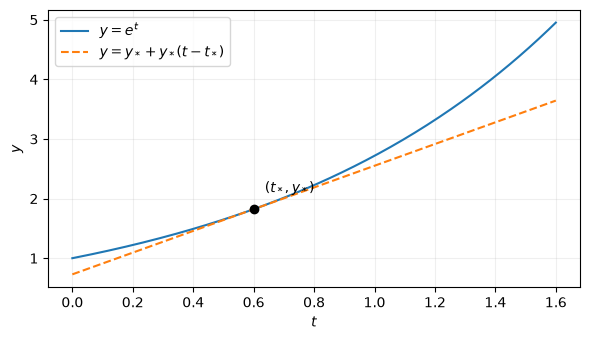

In [1]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 1.6, 200)
t_star = 0.6
y_star = np.exp(t_star)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(t, np.exp(t), label=r"$y=e^t$")
ax.plot(t, y_star * (1 + t - t_star), "--", label=r"$y=y_*+y_*(t-t_*)$")
ax.plot(t_star, y_star, "ko")
ax.annotate(r"$(t_*,y_*)$", (t_star, y_star), xytext=(8, 12), textcoords="offset points")
ax.set(xlabel="$t$", ylabel="$y$")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

***Figure 1.*** *The slope of an integral curve at a point is prescribed by the differential equation*

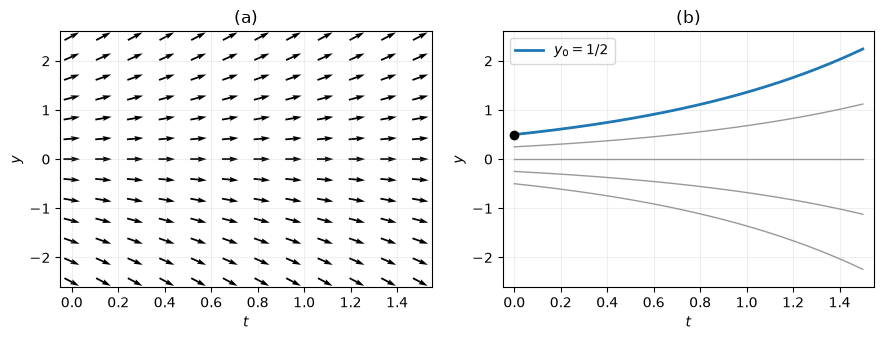

In [2]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 1.5, 200)
T, Y = np.meshgrid(np.linspace(0, 1.5, 12), np.linspace(-2.5, 2.5, 13))
length = np.sqrt(1 + Y**2)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].quiver(T, Y, 1 / length, Y / length, angles="xy", pivot="mid")
for y0 in [-0.5, -0.25, 0, 0.25, 0.5]:
    axes[1].plot(t, y0 * np.exp(t), color="0.6", linewidth=1)
axes[1].plot(t, 0.5 * np.exp(t), color="tab:blue", linewidth=2, label=r"$y_0=1/2$")
axes[1].plot(0, 0.5, "ko")
axes[1].legend()
for letter, ax in zip(["(a)", "(b)"], axes):
    ax.set(xlabel="$t$", ylabel="$y$", title=letter, xlim=(-0.05, 1.55), ylim=(-2.6, 2.6))
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

***Figure 2.*** *(a) A direction field; (b) integral curves of $y'=y$ and the curve selected by an initial condition*

The geometric interpretation of using an initial condition consists in selecting, from the family of integral curves, the specific curve that passes through the fixed point $(t_0, y_0)$.

**Definition 1 (Cauchy problem).** The problem of finding, for $t > t_0$, a solution $y(t)$ of differential equation (1) that satisfies the initial condition (2) will be called the Cauchy problem. In some cases, the behavior of the solution for all $t > t_0$ is of interest. However, more often one restricts the problem to determining the solution on a finite interval $[t_0, T]$.

### Solvability of the Cauchy Problem

Let $\Pi_T$ be the set of points $(t, y)$ satisfying the conditions $t_0 \leq t \leq T$, $-\infty < y < \infty$; we will call this set a strip.

We state one of the theorems concerning the solvability of the Cauchy problem.

**Theorem 1 (existence and uniqueness).** Let the function $f(t, y)$ be defined and continuous in the strip $\Pi_T$. Suppose also that it satisfies the Lipschitz condition:

$$
|f(t, y_1) - f(t, y_2)| \leq L |y_1 - y_2| \tag{3}
$$

for all $t_0 \leq t \leq T$ and arbitrary $y_1, y_2$, where $L$ is a nonnegative constant (the Lipschitz constant).

Then, for every initial value $y_0$, there exists a unique solution $y(t)$ to the Cauchy problem (1), (2), defined on the interval $[t_0, T]$.

**Remark 1 (scope of the theorem).** The Lipschitz constant is uniform in $t$ and in all $y\in\mathbb R$. These global assumptions guarantee existence on the entire prescribed interval. Local Lipschitz continuity in $y$ gives local existence and uniqueness, but does not by itself exclude finite-time blow-up; for example, $y'=y^2$, $y(0)=1$ has the solution $y(t)=1/(1-t)$ only up to $t=1$.

**Remark 2 (derivative criterion).** For functions $f$ that are differentiable with respect to $y$, condition (3) holds if and only if, for all $(t, y) \in \Pi_T$, the inequality

$$
|f'_y(t, y)| \leq L \tag{4}
$$

is satisfied. Therefore, condition (4) may also be called the Lipschitz condition.

**Remark 3 (one-sided Lipschitz condition).** Theorem 1 remains valid if, in its formulation, the Lipschitz condition (3) is replaced by the less restrictive one-sided Lipschitz condition

$$
\bigl(f(t, y_1) - f(t, y_2)\bigr)\,(y_1 - y_2) \leq \sigma (y_1 - y_2)^2. \tag{5}
$$

Note that the constant $\sigma$ appearing in this condition may have any sign.

For functions $f$ that are differentiable with respect to $y$, condition (5) holds if and only if, for all $(t, y) \in \Pi_T$, the inequality

$$
f'_y(t, y) \leq \sigma \tag{6}
$$

is satisfied.

Clearly, for functions that satisfy the Lipschitz condition with constant $L$, the one-sided condition is automatically satisfied with $\sigma=L$; a smaller constant may be available.

**Example 1.** The function $f(t,y) = \cos(t + y)$ satisfies the Lipschitz condition with constant $L = 1$, since $f'_y = -\sin(t + y)$ and $|f'_y| \leq 1$. It follows that the solution to the Cauchy problem $y' = \cos(t + y)$, $y(t_0) = y_0$ exists and is unique on any interval $[t_0, T]$.

**Example 2.** The function $f(t, y) = t - y^3$ does not satisfy the global Lipschitz condition on the strip, because $f'_y = -3y^2$ and the magnitude of this derivative is unbounded. At the same time, the one-sided condition (6) is satisfied with constant $\sigma = 0$. Therefore, we may conclude that the solution of the Cauchy problem $y' = t - y^3$, $y(t_0) = y_0$ exists and is unique on any interval $[t_0, T]$.

**Example 3.** The function $f(t, y) = t + y^3$ does not satisfy the one-sided condition (6), since the partial derivative $f'_y = 3y^2$ is unbounded above. Therefore, the question of the solvability of the Cauchy problem $y' = t + y^3$, $y(t_0) = y_0$ requires additional analysis.

The one-sided condition bounds the separation of solutions, rather than the absolute size of $f_y'$. Together with continuity on the whole strip, it also prevents finite-time escape: setting $y_2=0$ in (5) gives $y f(t,y)\leq \sigma y^2+|y|\,|f(t,0)|$, and $f(t,0)$ is bounded on $[t_0,T]$.

We now note a useful result relating the smoothness of the solution to that of the right-hand side.

**Theorem 2 (smoothness of the solution).** Let the function $f$ be continuously differentiable $m$ times ($m\geq1$) in a neighborhood of the strip $\Pi_T$. Then, if the function $y$ is a solution of the Cauchy problem (1), (2) on the interval $[t_0, T]$, it is continuously differentiable $m + 1$ times on this interval.

This statement follows directly from the possibility of differentiating the identity $y'(t) \equiv f(t, y(t))$ at least $m$ times. $\square$

In what follows, we will assume that the functions $f$ and $y$ are differentiable as many times as needed for the numerical methods under consideration.

### Stability of the Solution of the Cauchy Problem on a Finite Interval

This question is very important for understanding the behavior of numerical methods for integrating differential equations. We begin by examining how errors introduced into the initial values propagate. Let $y_0^*$ be a perturbed initial value, $\varepsilon_0 = y_0 - y_0^*$ its error, and let $y^*(t)$ be the solution of the corresponding Cauchy problem

$$
(y^*)'(t) = f(t, y^*(t)), \tag{7}
$$

$$
y^*(t_0) = y_0^*. \tag{8}
$$

For the following derivation, assume additionally that $f_y'$ is continuous. Subtract equation (7) from equation (1) and use the mean value formula:

$$
\begin{aligned}
f(t,y)-f(t,y^*)&=\lambda(t)(y(t)-y^*(t)),\\
\lambda(t)&=\int_0^1 f_y'(t,y^*(t)+s(y(t)-y^*(t)))\,ds.
\end{aligned}\tag{9}
$$

This integral form avoids choosing intermediate points as functions of $t$. It also gives $\lambda(t)\leq\sigma$ under the one-sided condition.

As a result, the error $\varepsilon(t) = y(t) - y^*(t)$ satisfies the differential equation

$$
\varepsilon'(t) = \lambda(t)\,\varepsilon(t) \tag{10}
$$

and the initial condition

$$
\varepsilon(t_0) = \varepsilon_0. \tag{11}
$$

The solution of problem (10), (11) is given by

$$
\varepsilon(t) = \varepsilon_0 \exp\left\{ \int_{t_0}^t \lambda(\tau)\, d\tau \right\}. \tag{12}
$$

Thus, the quantity

$$
C(t)=\exp\left\{\int_{t_0}^t\lambda(\tau)\,d\tau\right\}.\tag{13}
$$

plays the role of an error growth coefficient in the Cauchy problem.

Note that the sign of the derivative $f'_y$ has a significant influence on the behavior of the error $\varepsilon(t)$. If $f'_y > 0$, then the quantity $C(t)$, and hence the magnitude of the error, increases monotonically. In this case, the corresponding integral curves diverge. An illustration of this error behavior is shown in Figure 3a. The error behaves differently when $f'_y < 0$. Here, $C(t)$ and $|\varepsilon(t)|$ decrease monotonically as $t$ increases, and the corresponding integral curves converge. The magnitude of an initial perturbation decreases (Figure 3b), but pointwise negativity of the derivative alone does not guarantee convergence to zero as $t\to\infty$. When the derivative $f'_y$ changes sign, the behavior of the error may be more complex.

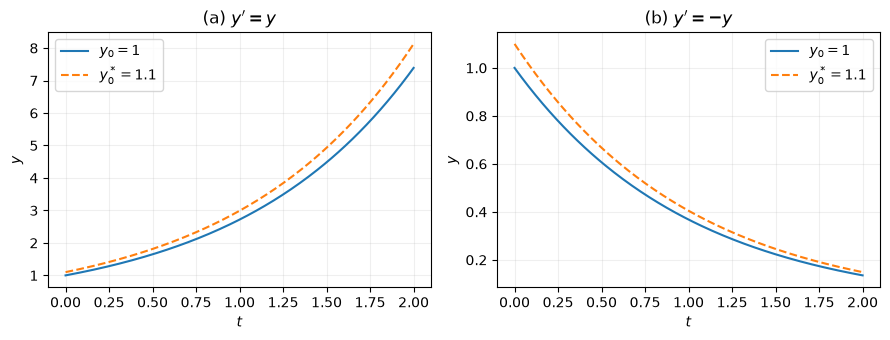

In [3]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 2, 200)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, lam, title in zip(axes, [1, -1], [r"(a) $y'=y$", r"(b) $y'=-y$"]):
    ax.plot(t, np.exp(lam * t), label=r"$y_0=1$")
    ax.plot(t, 1.1 * np.exp(lam * t), "--", label=r"$y_0^*=1.1$")
    ax.set(xlabel="$t$", ylabel="$y$", title=title)
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

***Figure 3.*** *Perturbations of initial data grow for $y'=y$ and decay for $y'=-y$*

It is important to note that in any case the fulfillment of the one-sided Lipschitz condition (5) guarantees that the error growth coefficient $C(t)$ remains bounded when the problem is solved on a finite interval $[t_0, T]$. Indeed, in this situation

$$
\int_{t_0}^t \lambda(\tau)\, d\tau 
\leq \int_{t_0}^t \sigma\, d\tau 
= \sigma (t - t_0) \tag{14}
$$

and therefore $C(t) \leq K(T)$ for all $t_0 \leq t \leq T$, where

$$
K(T) = 
\begin{cases}
e^{\sigma (T - t_0)}, & \text{if } \sigma > 0, \\
1, & \text{if } \sigma \leq 0.
\end{cases} \tag{15}
$$

Thus, under the condition $f'_y \leq \sigma$, the following estimate holds:

$$
\max_{t_0 \leq t \leq T} |y(t) - y^*(t)| \leq K(T)\,|y_0 - y_0^*|, \tag{16}
$$

which expresses the stability on the finite interval $[t_0, T]$ of the solution of the Cauchy problem with respect to initial data.

The estimate remains valid without differentiability of $f$: it follows directly from the one-sided Lipschitz condition by estimating the difference of the two solutions.

### Model Equation

The error behaves in the simplest way when solving the linear equation

$$
y'(t) = \lambda\, y(t) + f(t) \tag{17}
$$

with a constant real coefficient $\lambda$ and a continuous forcing term $f(t)$; here $f(t)$ is independent of $y$. In this case, the error $\varepsilon$ satisfies the equation $\varepsilon'(t) = \lambda\, \varepsilon(t)$ and is given by the formula

$$
\varepsilon(t) = \varepsilon_0\, e^{\lambda (t - t_0)}. \tag{18}
$$

Since the function $f(t)$ does not affect the character of error propagation, it is natural, when studying stability with respect to initial values, to restrict ourselves to the case $f(t) \equiv 0$ and consider the equation

$$
y'(t) = \lambda\, y(t). \tag{19}
$$

Equation (19) is often called the *model equation*. It plays an important role in the analysis of numerical methods for solving the Cauchy problem.

As follows from formula (18), the magnitude of the error in solving equation (19) changes by a factor of $e$ over the time interval $\tau = \dfrac{1}{|\lambda|}$, provided $\lambda\ne0$.

Therefore, the quantity $\tau = \dfrac{1}{|\lambda|}$ is sometimes called the *time constant* or *time scale* of the model equation (19). For the linear model we may also allow complex $y$ and $\lambda$. The time scale of growth or decay of the magnitude is then $\tau = \dfrac{1}{|\operatorname{Re}\lambda|}$ when $\operatorname{Re}\lambda\ne0$. If $\operatorname{Re}\lambda=0$, the magnitude is constant, so there is no finite growth or decay time scale; a nonzero imaginary part describes oscillations.

Assume $f_y'$ is continuous. When studying the propagation of a small perturbation introduced into the solution $y(t)$ of the equation $y' = f(t, y)$ in a small neighborhood of a point $\tilde t$, the value of the coefficient $\lambda(t)$ in equation (10) is close to the constant $\tilde\lambda = f'_y(\tilde t, y(\tilde t))$. Therefore, for $t \approx \tilde t$ the approximate equality $\varepsilon'(t) \approx \tilde\lambda\, \varepsilon(t)$ holds. This means that the behavior of the error for the equation $y' = \tilde\lambda y$ models the local error propagation for the general equation (1). The corresponding time constant is the *local time constant*

$$
\tau(\tilde t) = \dfrac{1}{|\tilde\lambda|}
= \dfrac{1}{|f'_y(\tilde t, y(\tilde t))|}. \tag{20}
$$

This value changes as the point $\tilde t$ changes. The local time scale in (20) is used when the derivative is nonzero. Freezing the coefficient is a local approximation, not a global error estimate for a nonlinear equation.

### Stability with Respect to the Right-Hand Side

Will the solution of the Cauchy problem be stable not only with respect to the error $\varepsilon_0$ in specifying the initial value, but also with respect to errors $\psi(t)$ in specifying the right-hand side of the equation? A positive answer to this question is given by the following theorem.

**Theorem 3 (perturbations of initial data and forcing).** Let the assumptions of Theorem 1 be satisfied, and let $\psi$ be continuous on $[t_0,T]$. Let $y(t)$ be the solution of problem (1), (2), and let $y^*(t)$ be the solution of the problem

$$
(y^*)'(t) = f(t, y^*(t)) + \psi(t), \tag{21}
$$

$$
y^*(t_0) = y_0^*. \tag{22}
$$

Then the following estimate holds:

$$
\max_{t_0 \leq t \leq T} |y(t) - y^*(t)| 
\leq K(T) \left( |y_0 - y_0^*| + \int_{t_0}^T |\psi(\tau)|\, d\tau \right), \tag{23}
$$

which expresses the stability of the solution of the Cauchy problem on the finite interval $[t_0, T]$ with respect to initial values and the right-hand side. Here $K(T) = e^{L(T - t_0)}$.

**Remark 4 (conditioning).** The quantity $K(T)$ is an upper bound for an absolute condition number for the Cauchy problem. If, in Theorem 1, the Lipschitz condition (3) is replaced by the one-sided condition (5), then estimate (23) holds with the constant $K(T)$ defined by formula (15).

Here the perturbation of the forcing is measured in the integral norm $\int_{t_0}^T|\psi(\tau)|\,d\tau$. If it is instead measured by its maximum magnitude, the bound contains the additional factor $T-t_0$. The bound $K(T)$ need not be sharp.

### Stability of the Solution on an Unbounded Interval

In many applied problems, particular interest lies in studying processes described by differential equations over large time intervals. In such situations, it is important for the Cauchy problem to possess the property of stability on any finite interval. If the quantity $K(T)$ in inequality (23) can grow without bound as $T$ increases, this means that an exponential growth of the error as $T \to \infty$ is allowed even for an arbitrarily small perturbation of $y_0$. A growing upper bound alone does not prove that every perturbation grows. However, when the problem actually amplifies perturbations, maintaining a prescribed accuracy over a long interval may require increasingly accurate input data and computations.

**Example 4.** Consider the Cauchy problem $y'(t) = y(t) - \sin t + \cos t$, $y(0) = 0$. Its solution, as is easy to verify, is the function $y(t) = \sin t$.

Introduce an error into the initial value by replacing the condition $y(0) = 0$ with $y(0) = \varepsilon$. The solution of the corresponding problem is then $y(t) = \sin t + \varepsilon e^t$. The error term $\varepsilon e^t$ grows rapidly as $t$ increases and, as shown in Figure 4, for even moderately large $t$ its magnitude becomes unacceptably large.

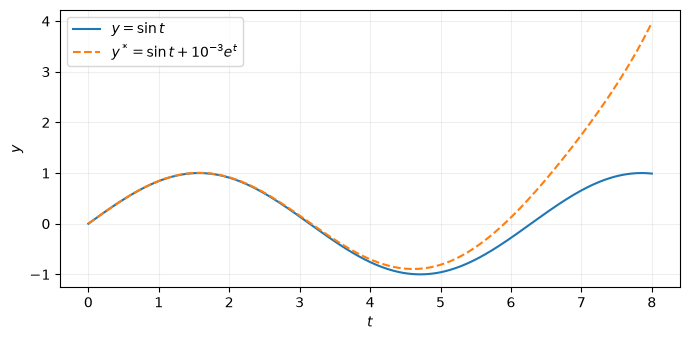

In [4]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 8, 400)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t, np.sin(t), label=r"$y=\sin t$")
ax.plot(t, np.sin(t) + 1e-3 * np.exp(t), "--", label=r"$y^*=\sin t+10^{-3}e^t$")
ax.set(xlabel="$t$", ylabel="$y$")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

***Figure 4.*** *The solutions $\sin t$ and $\sin t+\varepsilon e^t$ for $\varepsilon=10^{-3}$*

For a bound on the amplification of initial-data errors that is independent of $T$, it is sufficient to require that the right-hand side of the equation satisfy the inequality $f'_y(t, y) \leq 0$ for all $t \geq t_0$ and all $y$. This also gives a uniform bound for forcing errors measured in the integral norm. It does not in general give a uniform bound for persistent forcing measured in the maximum norm: for $y'=0$ and $\psi\equiv\delta$, the resulting error grows as $|\delta|(t-t_0)$. With a strict contraction condition, one can prove that if the condition $f'_y(t, y) \leq \sigma < 0$ holds, then the following estimate is valid:

$$
|y(t) - y^*(t)| \leq e^{\sigma (t - t_0)} |y_0 - y_0^*| 
+ \frac{1}{|\sigma|} \max_{t_0 \leq \tau \leq t} |\psi(\tau)|. \tag{24}
$$

Assume that $f$ is continuous on $[t_0,\infty)\times\mathbb R$ and that on each finite strip the one-sided condition holds with some constant $\sigma(T)$. Then solutions are defined for all $t\geq t_0$.

**Definition 2 (Lyapunov and asymptotic stability).** Fix $t_0$ and a solution $y$. Consider solutions $y^*$ of the same, unperturbed differential equation, so $\psi\equiv0$. The solution $y$ is Lyapunov stable if, for every $\epsilon>0$, there is $\delta>0$ such that $|y_0-y_0^*|<\delta$ implies $|y(t)-y^*(t)|<\epsilon$ for all $t\geq t_0$. It is asymptotically stable if it is Lyapunov stable and, for all sufficiently close initial values, $y^*(t)-y(t)\to0$ as $t\to\infty$.

**Proposition 1 (a sufficient stability estimate).** A sufficient condition for Lyapunov stability is

$$
\sup_{t\geq t_0}|y(t)-y^*(t)|\leq K|y_0-y_0^*|,\tag{25}
$$

where $K$ is independent of time and of the nearby initial value. This is a stronger, Lipschitz form of continuous dependence. Taking $\delta=\epsilon/(K+1)$ proves the assertion. $\square$

**Remark 5 (the model equation).** The solutions of the model equation (19) with a real parameter $\lambda$ are Lyapunov stable if and only if $\lambda \leq 0$, and asymptotically stable if and only if $\lambda < 0$. This conclusion follows directly from formula (18). If the parameter $\lambda$ is a complex number, then the same formula yields $|\varepsilon(t)| = |\varepsilon_0|\, e^{\operatorname{Re}\lambda\, (t - t_0)}$. Therefore, the solutions of the model equation are Lyapunov stable if and only if $\operatorname{Re}\lambda \leq 0$, and asymptotically stable if and only if $\operatorname{Re}\lambda < 0$.

**Corollary 1 (a sufficient contraction condition).** For the solution of the Cauchy problem (1), (2), with $\psi\equiv0$, a rough sufficient condition for Lyapunov stability is the inequality $f'_y \leq 0$. The condition $f'_y \leq \sigma$ with a constant $\sigma < 0$ implies asymptotic stability of the solution.

## Numerical Methods for Solving the Cauchy Problem. Basic Concepts and Definitions

### Grids and Grid Functions

**Definition 3 (grid and grid step).** The first step in constructing a numerical method for solving the Cauchy problem consists in replacing the interval $[t_0, T]$—the domain of continuous variation of the argument $t$—with a set $\overline{\omega}^h$, which consists of a finite number of points $t_0 < t_1 < \dots < t_N = T$ and is called a *grid*. The points $t_n$ themselves are called *grid nodes*, and the quantity $h_n = t_n - t_{n-1}$ is called the *grid step* (see Figure 5). To simplify the exposition, we will usually consider *uniform grids*, i.e., grids in which the step $h_n$ is constant. In this case, $h_n = h = \dfrac{T - t_0}{N}$ and $t_n = t_0 + nh$, $n = 0, 1, \ldots, N$.



***Figure 5.*** *A nonuniform grid (top) and a uniform grid (bottom)*

<details>
<summary>Figure 5: TikZ source</summary>

```latex
\documentclass[tikz,border=8pt]{standalone}
\begin{document}
\begin{tikzpicture}[x=10cm,y=1cm]
  \draw[gray] (0,1.2) -- (1,1.2);
  \foreach \x/\label in {0/{t_0},0.12/{t_1},0.4/{t_2},0.55/{t_3},0.85/{t_4},1/{t_N=T}} {
    \fill[blue!65!black] (\x,1.2) circle (1.5pt);
    \node[below=5pt] at (\x,1.2) {$\label$};
  }
  \draw[<->] (0.4,1.55) -- node[above] {$h_3$} (0.55,1.55);
  \draw[gray] (0,0) -- (1,0);
  \foreach \x/\label in {0/{t_0},0.2/{t_1},0.4/{t_2},0.6/{t_3},0.8/{t_4},1/{t_N=T}} {
    \fill[blue!65!black] (\x,0) circle (1.5pt);
    \node[below=5pt] at (\x,0) {$\label$};
  }
  \draw[<->] (0.2,0.35) -- node[above] {$h$} (0.4,0.35);
\end{tikzpicture}
\end{document}
```

</details>

**Definition 4 (grid function).** Alongside functions of a continuous argument, we will also consider *grid functions*, i.e., functions that are defined only at the grid nodes of $\overline{\omega}^h$. To distinguish grid functions from functions of a continuous argument, we will indicate the node index. For example, $u_n$ denotes the value of a grid function at the node $t_n$. For brevity, the values $u^h(t_n)$ of a grid function $u^h$ at the grid points $t_n$ will be denoted by $u_n^h$.

### Discrete Cauchy Problem

The next step in constructing a numerical method consists in replacing the Cauchy problem with its discrete analogue — a system of equations whose solution allows one to sequentially compute the values $y_1, y_2, \ldots, y_N$ of the grid function $y^h$, which serve as approximations to the values of the solution of the Cauchy problem at the grid nodes $\overline{\omega}^h$.

The construction of a specific numerical method is based on some way of replacing the differential equation $y' = f(t, y)$ with its discrete analogue — an equation of the form

$$
\frac{1}{h} \sum_{j=0}^k \alpha_j\, y_{n+1-j}
= \Phi(t_n, y_{n+1-k}, \ldots, y_n, y_{n+1}, h), \tag{26}
$$

which includes values of the grid function $y^h$ at $k+1$ consecutive points $t_{n+1-k}, \ldots, t_n, t_{n+1}$. Here $k\geq1$ is fixed, $N\geq k$, the real coefficients $\alpha_j$ are independent of $h$, and $\alpha_0\ne0$. We consider positive steps $h=(T-t_0)/N$. For implicit schemes, solvability of each step is also required.

In all methods considered in this chapter, the sum

$$
\frac{1}{h}
\left( \alpha_0 y_{n+1} + \alpha_1 y_n + \ldots + \alpha_k y_{n+1-k} \right) \tag{27}
$$

appearing on the left-hand side of equation (26) can be viewed as a finite-difference approximation of the derivative $y'$, in accordance with one of the numerical differentiation formulas. The right-hand side $\Phi$ of equation (26) can be viewed as a specially constructed approximation of the function $f$.

The value $y_{n+1}$ — the approximate solution at the next point — is obtained from equation (26). Previously computed values of the grid function $y^h$ at the points $t_{n+1-k}, \ldots, t_n$ are used in this process.

**Definition 5 (step number and discrete Cauchy problem).** Such methods are called *$k$-step methods*. To compute the grid function $y^h$ at the nodes of the grid $\overline{\omega}^h$ using a $k$-step method, one must specify $k$ initial values:

$$
y^h(t_0) = y_0,\quad
y^h(t_1) = y_1,\quad
\ldots,\quad
y^h(t_{k-1}) = y_{k-1}. \tag{28}
$$

We call the problem of computing the grid function $y^h$ that satisfies equation (26) for $n=k-1,\ldots,N-1$ and takes the prescribed initial values (28) the *discrete Cauchy problem*.

**Remark 6.** It is customary to regard equation (26) as defining a numerical method for solving the Cauchy problem. In what follows, we will identify the properties of the numerical method, the discrete equation (26), and the corresponding discrete Cauchy problem.

**Definition 6 (one-step and multistep methods).** For $k=1$, we use the normalized form $\alpha_0=1$, $\alpha_1=-1$; the normalization conditions are discussed below. Equation (26) then becomes

$$
\frac{y_{n+1} - y_n}{h} = \Phi(t_n, y_n, y_{n+1}, h). \tag{29}
$$

The corresponding method is called a *one-step method*. The computation of $y_{n+1}$ here uses only the previous value $y_n$. Therefore, one-step methods are often called *self-starting*. A method requiring $k>1$ previous values is called a *multistep method*. The extra starting values must be computed separately, for example by a one-step method.

**Example 5.** The simplest discrete analogue of differential equation (1) is

$$
\frac{y_{n+1} - y_n}{h} = f(t_n, y_n), \tag{30}
$$

which leads to the well-known Euler method.

**Example 6.** The Euler method is an example of a one-step method. The next value $y_{n+1}$ is computed using the formula

$$
y_{n+1} = y_n + h f(t_n, y_n). \tag{31}
$$



### Explicit and Implicit Methods

Implementing a numerical method on a computer requires constructing an algorithm that makes it possible to compute the solution of the given discrete Cauchy problem.

**Definition 7 (explicit and implicit methods).** In the case where the function $\Phi$ in equation (26) does **not** depend on $y_{n+1}$, computing the value of $y_{n+1}$ poses no difficulty and is carried out using the explicit formula

$$
y_{n+1}
= \alpha_0^{-1} \left[
- \sum_{j=1}^k \alpha_j\, y_{n+1-j}
+ h\, \Phi(t_n, y_{n+1-k}, \ldots, y_n, h)
\right]. \tag{32}
$$

Therefore, the corresponding methods are called *explicit*. In contrast, methods in which the function $\Phi$ depends on $y_{n+1}$ are called *implicit*. When implementing an implicit method, at each $n$ (that is, at each step), it becomes necessary to solve equation (26), generally nonlinear, with respect to $y_{n+1}$.

**Example 7.** The Euler method, in which $y_{n+1}$ is computed by the explicit formula (31), is an explicit method.

**Example 8.** The simplest example of an implicit method is the *implicit Euler method*, corresponding to the approximation of differential equation (1) by the discrete equation

$$
\frac{y_{n+1} - y_n}{h} = f(t_{n+1}, y_{n+1}). \tag{33}
$$

Another example of an implicit method is the *trapezoidal rule*:

$$
\frac{y_{n+1} - y_n}{h} =
\frac{1}{2}\, \bigl( f(t_n, y_n) + f(t_{n+1}, y_{n+1}) \bigr). \tag{34}
$$

In both methods, the value $y_{n+1}$ is defined implicitly. For a nonlinear $f$, an iterative solver is generally needed; for a linear $f$, the value may be obtained directly.

**Remark 7 (solvability of an implicit step).** If, with the previous values fixed, $\Phi$ is globally Lipschitz in $y_{n+1}$ with constant $M$, then $hM<|\alpha_0|$ is a sufficient condition for a unique step solution by the contraction principle. This is a sufficient condition, not a necessary one. For implicit Euler with $f(t,y)=\lambda y$ and $\lambda\leq0$, the denominator $1-h\lambda$ is nonzero for every $h>0$.

### Stability

If the solution of the discrete Cauchy problem is not stable with respect to small perturbations in the initial values and in the right-hand side of the equation, then the corresponding numerical method cannot be used in practical computations. We give a definition of stability sufficient for understanding the following discussion.

Introduce arbitrary small perturbations $\psi_n$ into the right-hand side of equation (26) and perturbations $\varepsilon_0, \varepsilon_1, \ldots, \varepsilon_{k-1}$ into the initial conditions (28), respectively. Let 

$$
y_0^* = y_0 - \varepsilon_0,\quad
y_1^* = y_1 - \varepsilon_1,\quad \ldots,\quad
y_{k-1}^* = y_{k-1} - \varepsilon_{k-1}.\tag{35}
$$

Let $y_n^{*\,h}$ be the solution of the corresponding perturbed problem

$$
\frac{1}{h} \sum_{j=0}^k \alpha_j\, y_{n+1-j}^*
= \Phi(t_n, y_{n+1-k}^*, \ldots, y_n^*, y_{n+1}^*, h)
+ \psi_n, \tag{36}
$$

$$
y^{*\,h}(t_0) = y_0^*,\;
y^{*\,h}(t_1) = y_1^*,\; \ldots,\;
y^{*\,h}(t_{k-1}) = y_{k-1}^*. \tag{37}
$$

**Definition 8 (stability on a finite interval).** We will call the discrete Cauchy problem (26), (28) and the corresponding numerical method *stable on a finite interval* (or simply *stable*) if, for all admissible $0<h\leq h_0$ and all sufficiently small perturbations for which the solutions exist (with $h_0$ sufficiently small), the inequality

$$
\max_{0 \leq n \leq N} |y_n - y_n^{*\,h}|
\leq \widetilde{K}(T) \left(
\max_{0 \leq s \leq k-1} |\varepsilon_s|
\;+\; \sum_{n = k-1}^{N-1} |\psi_n| \cdot h
\right), \tag{38}
$$

holds, where the quantity $\widetilde{K}(T)$ does not depend on $h$, on $\varepsilon_s$ $(0 \leq s \leq k-1)$, or on $\psi_n$ $(k-1 \leq n \leq N-1)$.

**Remark 8.** Inequality (38) is the discrete analogue of inequality (23), which expresses the stability of the solution of the (continuous) Cauchy problem. For one-step methods (i.e. when $k = 1$), inequality (38) takes the form

$$
\max_{0 \leq n \leq N} |y_n - y_n^{*\,h}|
\leq \widetilde{K}(T) \left(
|\varepsilon_0|
+ \sum_{n = 0}^{N-1} |\psi_n| \cdot h
\right), \tag{39}
$$

and the analogy with (23) becomes even more apparent. Indeed, the sum 

$$
\sum_{n=0}^{N-1} |\psi_n| \cdot h\tag{40}
$$

can be regarded as a discrete analogue of the integral 

$$
\int_{t_0}^T |\psi(t)|\, dt,\tag{41}
$$

constructed using the left-rectangle rule.

This definition concerns a fixed final time $T$ and a bound uniform as $h\to0$. It must be distinguished from absolute stability, which studies the behavior of a method for fixed $h\lambda$ over arbitrarily many steps. A stable continuous problem need not be well reproduced by a method at an arbitrary step size.

### Approximation

Let $y(t)$ be an arbitrary smooth function. Consider interior nodes $t=t_n$ for which the stencil lies in $[t_0,T]$, and let $h\to0$ through admissible grids. The convergence required for the error bounds below is uniform over these nodes. We assume that replacing in formula (27) the values $y_{n+1-j}$ of the grid function $y^h$ by the corresponding values $y(t - (j - 1)h)$ of the function $y$ gives the quantity

$$
\frac{1}{h}
\left( \alpha_0 y(t + h) + \alpha_1 y(t) + \ldots + \alpha_k y\bigl(t - (k - 1)h\bigr) \right), \tag{42}
$$

which tends to $y'(t)$ as $h \to 0$.

Similarly, we assume that

$$
\Phi\bigl(t,\,
y(t - (k - 1)h), \ldots, y(t), y(t + h), h\bigr)
\;\longrightarrow\;
f(t, y(t)) \quad \text{as } h \to 0. \tag{43}
$$

**Proposition 2 (normalization of the difference operator).** From these assumptions it follows that the coefficients $\alpha_0, \alpha_1, \ldots, \alpha_k$ must satisfy the conditions

$$
\sum_{j=0}^k\alpha_j=0,\quad\sum_{j=0}^k(1-j)\alpha_j=1. \tag{44}
$$

**Proof.** For $y(t) \equiv 1$ the quantity (42) becomes $\overline{\alpha}/h$, where $\overline{\alpha} = \sum_{j=0}^k \alpha_j$. By assumption, $\overline{\alpha}/h \to y'(t) = 0$ as $h \to 0$. This is possible only if $\overline{\alpha} = 0$, which proves the first equality in (44). Applying (42) to $y(t)=t$ then gives $\sum_{j=0}^k(1-j)\alpha_j=1$, which proves the second equality. $\square$

Let $y(t)$ be the solution of the Cauchy problem (1), (2).

**Definition 9 (approximation error).** We call the grid function $\psi_n^h$ defined by

$$
\psi_n^h =
\frac{1}{h} \sum_{j=0}^k \alpha_j\, y(t_{n+1-j})
- \Phi\bigl(t_n, y(t_{n+1-k}), \ldots, y(t_n), y(t_{n+1}), h\bigr),
\tag{45}
$$

the *approximation error* of the discrete equation (26) on the solution $y$. This formula, written as

$$
\frac{1}{h} \sum_{j=0}^k \alpha_j\, y(t_{n+1-j})
= \Phi\bigl(t_n, y(t_{n+1-k}), \ldots, y(t_n), y(t_{n+1}), h\bigr)
+ \psi_n^h, \tag{46}
$$

shows that the function $y(t)$ satisfies equation (26) up to the approximation error $\psi_n^h$.

The grid function $\psi_n^h$ is used for a preliminary estimate of how accurately the differential equation is approximated by its discrete analogue.

**Definition 10 (consistency and approximation order).** We say that the numerical method (26) *approximates the differential equation (1)* if

$$
\max_{k-1 \leq n \leq N-1} |\psi_n^h| \to 0 \quad \text{as } h \to 0, \tag{47}
$$

and that it *approximates it with order $p$* if the estimate

$$
\max_{k-1 \leq n \leq N-1} |\psi_n^h|
\leq C h^p,\quad p > 0, \tag{48}
$$

holds for all sufficiently small admissible $h$, with $C$ independent of $h$ and of the node index.

**Definition 11 (local error).** For one-step methods (29), instead of the approximation error, one often uses another quantity to assess the quality of the method — the *local error*. Let $y_{n+1}$ be the value obtained from the equation

$$
\frac{y_{n+1} - y(t_n)}{h}
= \Phi\bigl(t_n, y(t_n), y_{n+1}, h\bigr), \tag{49}
$$

i.e., from equation (29) in which $y_n$ is replaced by the exact value of the solution of the differential equation at the point $t = t_n$. The difference $l_n = y(t_{n+1}) - y_{n+1}$ is called the *local error of the method (or the error per step)*. In other words, $l_n$ measures the error made on a single step of the method under ideal (exact) input data.

For an explicit one-step method, $\Phi$ does not depend on its last solution argument, so the definitions give

$$
l_n=h\psi_n^h.\tag{50}
$$

For an implicit method, the corresponding identity is

$$
l_n=h\psi_n^h+h\bigl[\Phi(t_n,y(t_n),y(t_{n+1}),h)-\Phi(t_n,y(t_n),y_{n+1},h)\bigr].\tag{51}
$$

If $\Phi$ is Lipschitz in its new-value argument with constant $M$ independent of $h$ and $hM<1$, then

$$
\frac{h|\psi_n^h|}{1+hM}\leq |l_n|\leq\frac{h|\psi_n^h|}{1-hM}.\tag{52}
$$

Thus an approximation error $O(h^p)$ gives a local error $O(h^{p+1})$, under these assumptions. The approximation order $p$ does not determine whether a method is explicit or implicit.

### Convergence

Let $y(t)$ be the solution of the Cauchy problem.

**Definition 12 (global error).** We call the *global error* (or simply the *error*) of a numerical method the grid function $\varepsilon^h$ with values $\varepsilon_n = y(t_n) - y_n$ at the grid nodes $t_n$. As a measure of the absolute error of the method we take the quantity

$$
E(h) = \max_{0 \leq n \leq N} |y(t_n) - y_n|. \tag{53}
$$

**Definition 13 (convergence and order of accuracy).** A numerical method for solving the Cauchy problem is called *convergent* if $E(h) \to 0$ as $h \to 0$. We say that a method *converges with order $p$* (or has *order of accuracy $p$*) if the error satisfies the estimate $E(h) \leq C h^p$, $p > 0$, for all sufficiently small admissible $h$, with $C$ independent of $h$.

We now show that for a *stable* numerical method, the existence of an approximation of order $p$ implies convergence of the same order. We assume that the initial values $y_0, y_1, \ldots, y_{k-1}$ are given with $p$-th order accuracy, i.e.,

$$
\max_{0 \leq n \leq k-1} |y(t_n) - y_n| \leq C_0 h^p. \tag{54}
$$

The following is the main theorem.

**Theorem 4 (stability and approximation imply convergence).** Let a numerical method be stable on a finite interval and have approximation order $p$. Assume that the exact grid solution and the numerical solution lie in the domain where the stability bound applies, with constants uniform in $h$. Then, if the initial values $y_0, \ldots, y_{k-1}$ are given with $p$-th order accuracy, the method also converges with $p$-th order accuracy.

**Proof.** Let $\psi_n$ denote the approximation error. Set $y_n^* = y(t_n)$. Equality (45) implies that the grid function $y_n^*$ is a solution of the discrete Cauchy problem (36), (37). Stability of the method implies inequality (38), which, using the fact that $y_n^* = y(t_n)$, can be rewritten as

$$
\begin{gathered}
\max_{0 \leq n \leq N} |y(t_n) - y_n|\leq\\
\leq \widetilde{K}(T)
\left(
\max_{0 \leq s \leq k-1} |y(t_s) - y_s|
+ \sum_{n=k-1}^{N-1} |\psi_n| \cdot h
\right).
\end{gathered}
\tag{55}
$$

Taking into account that

$$
\sum_{n=k-1}^{N-1} |\psi_n| \cdot h
\leq (T - t_0) \max_{k-1 \leq n \leq N-1} |\psi_n|
\leq (T - t_0)\, C h^p, \tag{56}
$$

the right-hand side of (55) is estimated by

$$
\widetilde{K}(T)\, \left( C_0 + (T - t_0) C \right) h^p. \tag{57}
$$

Thus,

$$
\max_{0 \leq n \leq N} |y(t_n) - y_n|
\leq C_1 h^p, \tag{58}
$$

which proves convergence of the method with order $p$. $\square$

### Connection with the Problem of Computing an Integral

There is a close connection between the problem of solving the Cauchy problem and the problem of computing an integral with a variable upper limit:

$$
y(t) = \int_{t_0}^{t} f(\tau)\, d\tau,\quad t_0 \leq t \leq T. \tag{59}
$$

Indeed, evaluating the integral (59) is equivalent to solving the Cauchy problem

$$
y'(t) = f(t),\quad y(t_0) = 0, \tag{60}
$$

which is a special case of the more general problem (1), (2).

Thus, every numerical method for solving the Cauchy problem generates a corresponding numerical integration method. For example, the Euler method $y_{n+1} = y_n + h f(t_n)$ leads to the *left rectangle rule*:

$$
y(t_n) \approx y_n = h \sum_{i=0}^{n-1} f(t_i). \tag{61}
$$

The implicit Euler method $y_{n+1} = y_n + h f(t_{n+1})$ gives the *right rectangle rule*:

$$
y(t_n) \approx y_n = h \sum_{i=1}^{n} f(t_i). \tag{62}
$$

And the trapezoidal rule (34) results in the well-known *trapezoidal formula*:

$$
y(t_n) \approx \frac{h}{2} \sum_{i=1}^{n} \bigl( f(t_{i-1}) + f(t_i) \bigr). \tag{63}
$$

Using formula (61) as an example, we can easily see the difference between local and global errors. The *local error* is the error made on a single elementary interval:

$$
l_n = \int_{t_n}^{t_{n+1}} f(t)\, dt - h f(t_n), \tag{64}
$$

while the *global error* is the accumulated error:

$$
\varepsilon_n = \int_{t_0}^{t_n} f(t)\, dt - h \sum_{i=0}^{n-1} f(t_i). \tag{65}
$$

In this case, due to the linearity of problem (59), the global error is simply the sum of the local errors:

$$
\varepsilon_n = \sum_{\ell=0}^{n-1} l_\ell. \tag{66}
$$

When $f$ depends on $y$, the global error is generally not the unweighted sum of local errors, even for a linear equation such as $y'=\lambda y$. Depending on the behavior of the integral curves, the global error may turn out to be amplified (Figure 6a) or damped (Figure 6b) as local errors propagate. Their signs and possible cancellation also matter.

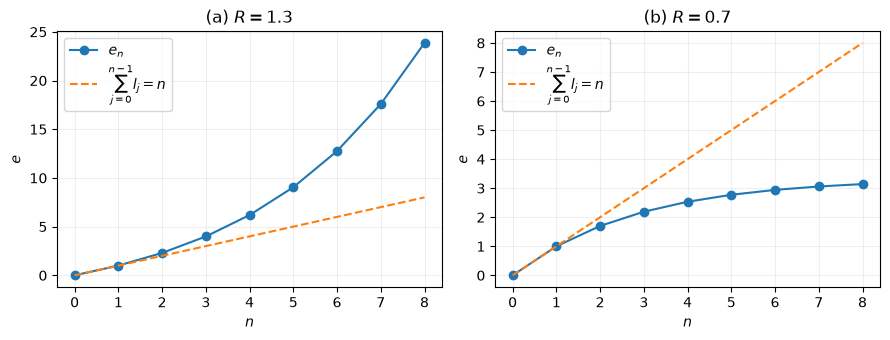

In [5]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(9)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, R, title in zip(axes, [1.3, 0.7], [r"(a) $R=1.3$", r"(b) $R=0.7$"]):
    # Each local error is one; its contribution is propagated by the factor R.
    e = np.zeros(len(n))
    for j in range(len(n) - 1):
        e[j + 1] = R * e[j] + 1
    ax.plot(n, e, "o-", label=r"$e_n$")
    ax.plot(n, n, "--", label=r"$\sum_{j=0}^{n-1}l_j=n$")
    ax.set(xlabel="$n$", ylabel="$e$", title=title)
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

***Figure 6.*** *Contributions $l_j$ to a scalar error recurrence $e_{j+1}=R e_j+l_j$: amplification for $R>1$ and damping for $0<R<1$, with equal positive local errors*

**Example 9 (checking the error orders).** For $y'=y$, $y(0)=1$, explicit Euler started from the exact value gives

$$
\begin{aligned}
\psi_n^h&=e^{t_n}\left(\frac{e^h-1}{h}-1\right)=\tfrac12 e^{t_n}h+O(h^2),\\
l_n&=e^{t_n}(e^h-1-h)=\tfrac12 e^{t_n}h^2+O(h^3).
\end{aligned}\tag{67}
$$

At $T=1$, let $h=1/N$. Euler gives $y_N=(1+h)^N$, hence

$$
y(1)-y_N=e-(1+h)^{1/h}=\frac e2h+O(h^2).\tag{68}
$$

The local error is of second order in $h$, while the global error is of first order. Halving the step therefore asymptotically halves the global error, rather than dividing it by four.

## References

1. **E. Hairer, S. P. Nørsett, G. Wanner.** *Solving Ordinary Differential Equations I: Nonstiff Problems.* 2nd revised edition. Springer, 1993. Initial value problems, local errors, stability, and convergence.
2. **J. C. Butcher.** *Numerical Methods for Ordinary Differential Equations.* 3rd edition. Wiley, 2016. One-step and multistep methods.
3. **A. Iserles.** *A First Course in the Numerical Analysis of Differential Equations.* 2nd edition. Cambridge University Press, 2009. Discretization, error propagation, and stability.